# Explore the Data

In [49]:
%pip install kagglehub scikit-learn matplotlib numpy ipywidgets pandas pyarrow seaborn spacy
!python3 -m spacy download en_core_web_lg
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import spacy
from sklearn.metrics.pairwise import cosine_similarity


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.7/400.7 MB 38.9 MB/s  0:00:09:00:0100:01

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_lg')


In [50]:
data = pd.read_parquet("train_set.parquet")
data.head(10)

,X,Y,Unique Squirrel ID,Hectare,Shift,Date,Hectare Squirrel Number,Age,Primary Fur Color,Highlight Fur Color,...,Runs from,Other Interactions,Lat/Long,diseased,prev_tmin_c,prev_tmax_c,prev_precip_mm,park_event_count,nearby_event_count,nearest_event_meters
0,-73.961570,40.795128,35A-AM-1014-03,35A,AM,2018-10-14,3,Adult,Gray,White,...,False,NaN,POINT (-73.9615696577673 40.7951278622399),False,7.8,12.8,2.5,17,6,90.0
1,-73.969247,40.772259,10H-PM-1007-01,10H,PM,2018-10-07,1,Adult,Gray,White,...,False,NaN,POINT (-73.9692472299565 40.7722592187215),False,17.2,20.0,0.0,25,5,89.0
2,-73.975646,40.770356,6D-PM-1020-02,06D,PM,2018-10-20,2,Juvenile,Gray,NaN,...,True,NaN,POINT (-73.9756457597888 40.7703559775625),False,6.1,15.6,0.0,29,7,261.0
3,-73.973382,40.768733,5G-PM-1010-05,05G,PM,2018-10-10,5,Adult,Gray,Cinnamon,...,False,NaN,POINT (-73.9733820053679 40.7687330473562),False,18.9,25.0,0.0,34,5,261.0
4,-73.972464,40.769053,6G-AM-1008-02,06G,AM,2018-10-08,2,Juvenile,Gray,NaN,...,False,NaN,POINT (-73.9724642436394 40.7690526441109),False,19.4,26.1,0.0,6,1,412.0
5,-73.966471,40.787896,26A-PM-1006-06,26A,PM,2018-10-06,6,Adult,Gray,Cinnamon,...,False,studying us looking for food,POINT (-73.9664711607022 40.787896428768),False,15.6,21.7,0.0,32,0,608.0
6,-73.958967,40.795213,37C-AM-1012-04,37C,AM,2018-10-12,4,Adult,Gray,Cinnamon,...,False,NaN,POINT (-73.9589670987899 40.7952127039287),False,20.6,25.0,21.3,8,2,281.0
7,-73.967473,40.777213,16F-PM-1013-03,16F,PM,2018-10-13,3,Juvenile,Gray,Cinnamon,...,True,NaN,POINT (-73.96747266034902 40.7772125619715),False,10.6,20.0,10.9,29,6,357.0
8,-73.974515,40.765542,1G-AM-1006-04,01G,AM,2018-10-06,4,Adult,Gray,White,...,False,NaN,POINT (-73.9745152462626 40.76554155159081),False,15.6,21.7,0.0,21,3,225.0
9,-73.952819,40.792313,36I-AM-1017-02,36I,AM,2018-10-17,2,Adult,Gray,Cinnamon,...,False,NaN,POINT (-73.952819267977 40.7923130402793),False,8.3,15.6,0.3,11,3,288.0


# Correlation Matrix 


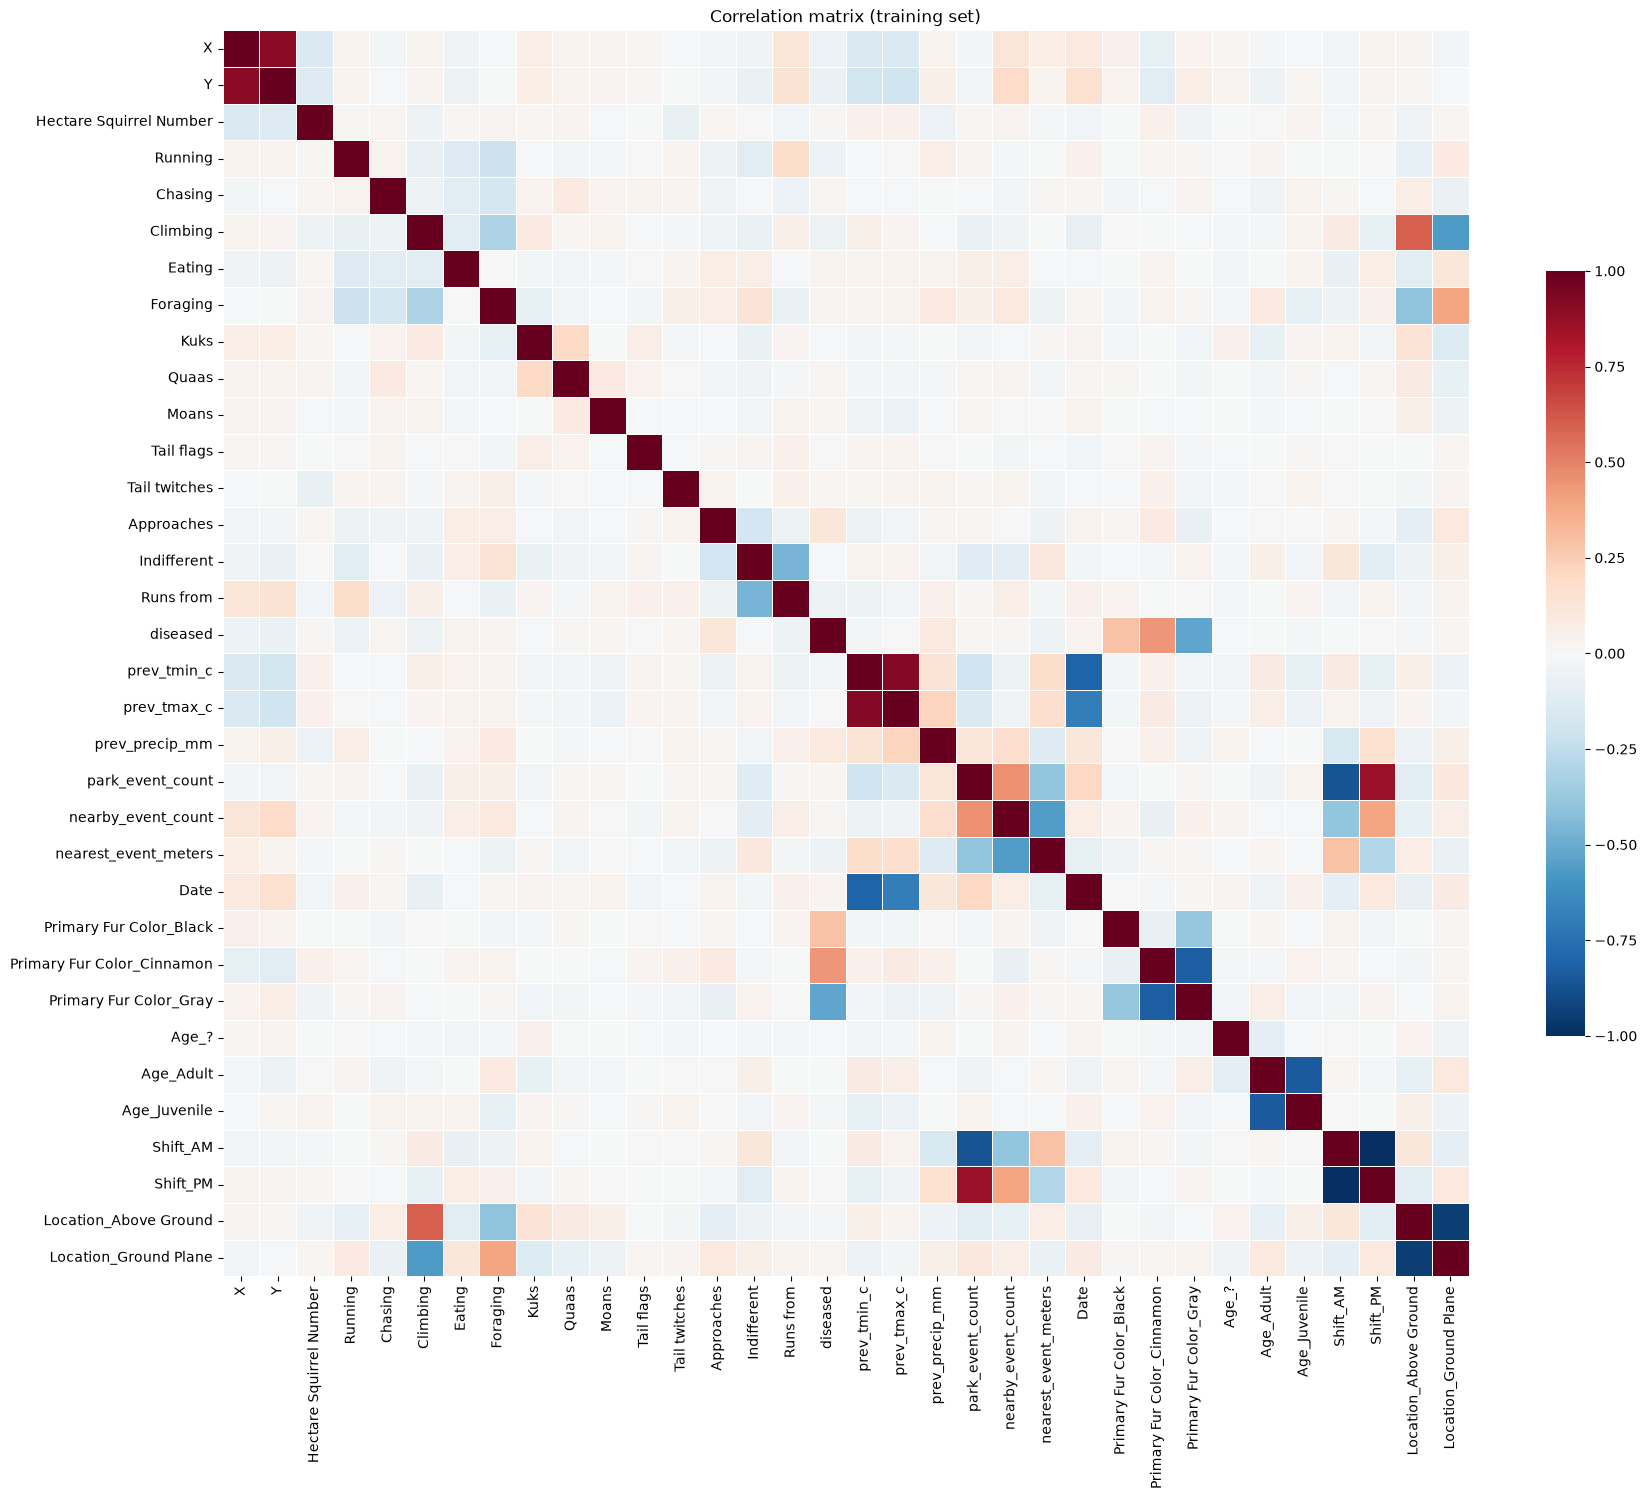

Primary Fur Color_Gray       -0.526
Primary Fur Color_Cinnamon    0.439
Primary Fur Color_Black       0.293
Approaches                    0.124
prev_precip_mm                0.098
Y                            -0.067
Running                      -0.061
X                            -0.060
Climbing                     -0.051
Runs from                    -0.048
nearest_event_meters         -0.047
Eating                        0.032
Foraging                      0.029
prev_tmin_c                  -0.025
Date                          0.024
Chasing                       0.022
Moans                         0.022
Location_Above Ground        -0.021
Location_Ground Plane         0.021
park_event_count              0.018
Age_Juvenile                 -0.018
Tail twitches                 0.018
Age_?                        -0.015
Quaas                         0.012
Hectare Squirrel Number       0.011
nearby_event_count            0.010
Indifferent                  -0.010
Kuks                        

In [51]:
# Correlation between every numeric and true/false column, including diseased.
# Small categorical columns are one hot encoded so they show up too.
# Date is added as the day of October, since a date can't be correlated directly.
corr_data = pd.concat(
    [data.select_dtypes(include=["number", "bool"]),data["Date"].dt.day.rename("Date"),pd.get_dummies(data[["Primary Fur Color", "Age", "Shift", "Location"]], dtype=float),],axis=1,
).astype(float)
corr = corr_data.corr()

plt.figure(figsize=(18, 15))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, linewidths=0.5, cbar_kws={"shrink": 0.6})
plt.title("Correlation matrix (training set)")
plt.tight_layout()
plt.show()

# Correlation of each feature with diseased, strongest first.
corr["diseased"].drop("diseased").sort_values(key=abs, ascending=False).round(3)

# Correlation Analysis 
Primary fur color had the strongest correlations with the disease label in the training set. Gray had a negative correlation (−0.53), while cinnamon (0.44) and black (0.29) had positive correlations.

# Feature Table


| Name | Dtype | Type | % Missing | Noisiness & Noise Type | Usefulness for Task | Distribution Type |
|---|---|---|---|---|---|---|
| X | float64 | Numerical | 0.0% | Low, it is the recorded point of the sighting | Medium, if Nutosis spreads between squirrels it could cluster in certain parts of the park | Multimodal with several peaks across the park |
| Y | float64 | Numerical | 0.0% | Low, it is the recorded point of the sighting | Medium, same reason as X, sick squirrels could be grouped in certain parts of the park | Bimodal with a south peak and a north peak and a dip in the middle |
| Unique Squirrel ID | str | Text | 0.0% | Low, a few IDs are repeated | Medium, we only use it to match the disease labels and see which squirrels were euthanized | Mostly unique, with three repeated entries in the training set. |
| Hectare | str | Categorical | 0.0% | Low, it is the grid square the volunteers were assigned | Medium, it could show where Nutosis is concentrated | Spread out over many squares with only a few sightings in each |
| Shift | str | Categorical | 0.0% | None, every sighting is either AM or PM | Low, AM and PM squirrels are sick at about the same rate so the time of day does not matter much | Fairly balanced, a little more PM than AM |
| Date | datetime64 | Date | 0.0% | None, every sighting has a valid date | Medium, a disease spreading over time makes sense for the business but we only have 11 days of data | A few dates with a lot of sightings and the rest with fewer |
| Hectare Squirrel Number | int64 | Numerical | 0.0% | Low, it is just the order the squirrels were counted | Low, it hints at how crowded a square is which could matter for spread but it shows almost no link to being sick | Right skewed, most squares have only a few squirrels |
| Age | str | Categorical | 3.6% | Low, some sightings are missing an age or have an invalid entry | Low, adults and juveniles are sick at about the same rate | Imbalanced, most are adults |
| Primary Fur Color | str | Categorical | 1.8% | Medium, volunteers judge the color by eye and some colors were fixed by hand | High, black and cinnamon squirrels are sick much more often than gray squirrels. This is our strongest signal | Imbalanced, most are gray |
| Highlight Fur Color | str | Categorical | 36.3%, missing means no highlight was recorded | Medium, some rows have more than one color in the same string | Medium, the sick rate changes a lot between highlight colors but it overlaps with the primary color | Imbalanced, a few combinations make up most rows |
| Combination of Primary and Highlight Color | str | Categorical | 0.0%, a + by itself means both colors are missing | Low, it repeats the two color columns | Low, it does not add anything beyond Primary and Highlight Fur Color | Imbalanced, a few combinations make up most rows |
| Color notes | str | Text | 94.1% | High, free text written differently by each volunteer | Low, it could flag colors the volunteer was unsure about but it is almost always empty | Sparse text |
| Location | str | Categorical | 2.0% | Low, a few sightings are missing it | Low, squirrels on the ground and above ground are sick at about the same rate | Imbalanced, most are on the ground |
| Above Ground Sighter Measurement | str | Text | 3.7% | High, FALSE is mixed in with numbers and most heights are rounded guesses | Low, it mostly repeats Location. Height could show if sick squirrels climb less | Right skewed, most heights are low with a few very high ones |
| Specific Location | str | Text | 84.2% | High, free text with inconsistent wording and capitalization | Low, it is rarely filled in | Sparse text |
| Running | bool | Categorical | 0.0% | Medium, volunteers record what they see and False could also mean they did not notice | Medium, running squirrels are sick less often which fits sick squirrels being less active | Imbalanced, most squirrels were not running |
| Chasing | bool | Categorical | 0.0% | Medium, volunteers record what they see and False could also mean they did not notice | Low, chasing squirrels are sick at about the same rate as the rest | Imbalanced, most squirrels were not chasing |
| Climbing | bool | Categorical | 0.0% | Medium, volunteers record what they see and False could also mean they did not notice | Medium, climbing squirrels are sick less often which also fits sick squirrels being less active | Imbalanced, most squirrels were not climbing |
| Eating | bool | Categorical | 0.0% | Medium, volunteers record what they see and False could also mean they did not notice | Low, eating squirrels are sick at about the same rate as the rest | Imbalanced, most squirrels were not eating |
| Foraging | bool | Categorical | 0.0% | Medium, volunteers record what they see and False could also mean they did not notice | Low, foraging squirrels are sick at about the same rate as the rest | Balanced, about half were foraging |
| Other Activities | str | Text | 85.2% | High, free text with inconsistent wording | Low, it is rarely filled in | Sparse text |
| Kuks | bool | Categorical | 0.0% | Medium, volunteers record what they see and False could also mean they did not notice | Low, it does not change the sick rate much and it is rare | Very imbalanced, almost no squirrels kuked |
| Quaas | bool | Categorical | 0.0% | Medium, volunteers record what they see and False could also mean they did not notice | Low, it does not change the sick rate much and it is rare | Very imbalanced, almost no squirrels quaaed |
| Moans | bool | Categorical | 0.0% | Medium, volunteers record what they see and False could also mean they did not notice | Low, only a handful of sightings so it is too rare to tell | Very imbalanced, almost no squirrels moaned |
| Tail flags | bool | Categorical | 0.0% | Medium, volunteers record what they see and False could also mean they did not notice | Low, it does not change the sick rate much | Very imbalanced, few squirrels flagged their tail |
| Tail twitches | bool | Categorical | 0.0% | Medium, volunteers record what they see and False could also mean they did not notice | Low, it does not change the sick rate much | Imbalanced, most squirrels did not twitch their tail |
| Approaches | bool | Categorical | 0.0% | Medium, volunteers record what they see and False could also mean they did not notice | High, squirrels that approached people are sick much more often than the rest. That fits a disease that changes behavior and it is our strongest behavior signal | Very imbalanced, few squirrels approached people |
| Indifferent | bool | Categorical | 0.0% | Medium, volunteers record what they see and False could also mean they did not notice | Low, indifferent squirrels are sick at about the same rate as the rest | Balanced, about half were indifferent |
| Runs from | bool | Categorical | 0.0% | Medium, volunteers record what they see and False could also mean they did not notice | Medium, sick squirrels run from people less often | Imbalanced, most squirrels did not run from people |
| Other Interactions | str | Text | 92.3% | High, free text with inconsistent wording | Low, it is rarely filled in | Sparse text |
| Lat/Long | str | Text | 0.0% | None, it is the same point as X and Y | Low, it is the same information as X and Y | Unique for each row |
| diseased | bool | Categorical | 0.0% | None, every sighting has a label | This is our target | Imbalanced, most squirrels are healthy |
| prev_tmin_c | float64 | Numerical | 0.0% | Low, it is one weather station reading for the whole park | Low, weather changes how many people report sightings but not whether a squirrel is sick | Discrete with only a few values and gaps |
| prev_tmax_c | float64 | Numerical | 0.0% | Low, it is one weather station reading for the whole park | Low, same reason as prev_tmin_c | Discrete with only a few values and gaps |
| prev_precip_mm | float64 | Numerical | 0.0% | Low, it is one weather station reading for the whole park | Low, it has the strongest link of the weather features but there are only a few values so it could just be certain days and not the rain | Right skewed, most days had no rain |
| park_event_count | int64 | Numerical | 0.0% | Medium, a permit means the event was scheduled, not that people came | Low, it describes how busy the park was and not the squirrel | Bimodal because AM shifts have fewer events than PM shifts |
| nearby_event_count | int64 | Numerical | 0.0% | Medium, event points are map centers and some permits have no location | Low, it describes how busy the area was and not the squirrel | Right skewed, most sightings had only a few events nearby |
| nearest_event_meters | float64 | Numerical | 0.0% | Medium, event points are map centers and some permits have no location | Low, how close an event was does not tell us much about the squirrel | Right skewed, most events were fairly close with a few far away |

## Target distribution

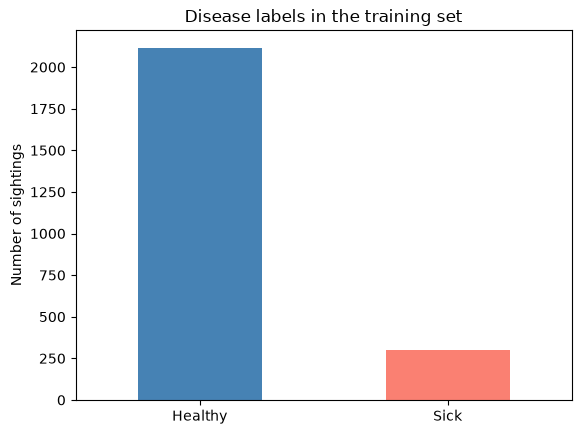

Healthy    2115
Sick        303
Name: count, dtype: int64
Sick sightings: 12.5%


In [52]:
counts = data["diseased"].value_counts().reindex([False, True])
counts.index = ["Healthy", "Sick"]

counts.plot.bar(color=["steelblue", "salmon"], rot=0)
plt.ylabel("Number of sightings")
plt.title("Disease labels in the training set")
plt.show()

print(counts)
print(f"Sick sightings: {data['diseased'].mean():.1%}")

Our target is `diseased`. We first check how many training sightings are labeled sick or healthy so we can understand the class balance. The training set contains 303 sick sightings and 2,115 healthy sightings. Only 12.5% are labeled sick, so the classes are imbalanced. Predicting every sighting as healthy would give 87.5% accuracy but miss every sick sighting. This supports using recall and precision to evaluate our models.

## Primary fur color and disease labels

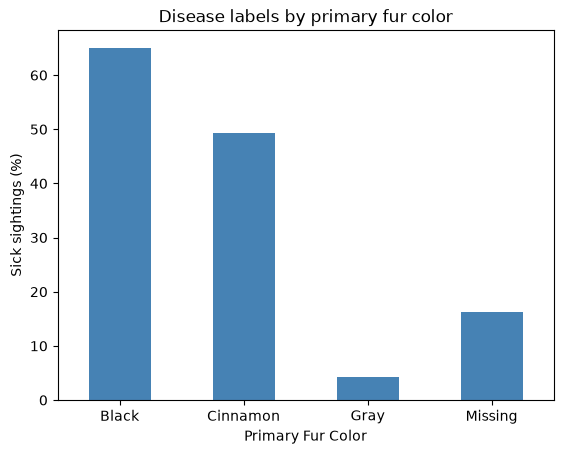

,sightings,sick_sightings,sick_rate
Primary Fur Color,,,
Black,80,52,0.650000
Cinnamon,326,161,0.493865
Gray,1969,83,0.042153
Missing,43,7,0.162791


In [53]:
color_summary = data.groupby("Primary Fur Color", dropna=False)["diseased"].agg(
    sightings="size",
    sick_sightings="sum",
    sick_rate="mean",
)
color_summary.index = color_summary.index.fillna("Missing")
(color_summary["sick_rate"] * 100).plot.bar(color="steelblue", rot=0)
plt.ylabel("Sick sightings (%)")
plt.title("Disease labels by primary fur color")
plt.show()

color_summary

We compare the percentage of sick sightings across primary fur colors and we also check the number of sightings in each group because some colors are reported much less often. About 65% of black sightings and 49% of cinnamon sightings are labeled sick, compared with about 4% of gray sightings. Primary fur color appears promising for classification in this training set. We should consider the group sizes when interpreting these percentages. The labels were created for this project, so this pattern does not establish a real biological relationship between fur color and disease.

## Behavior and disease labels

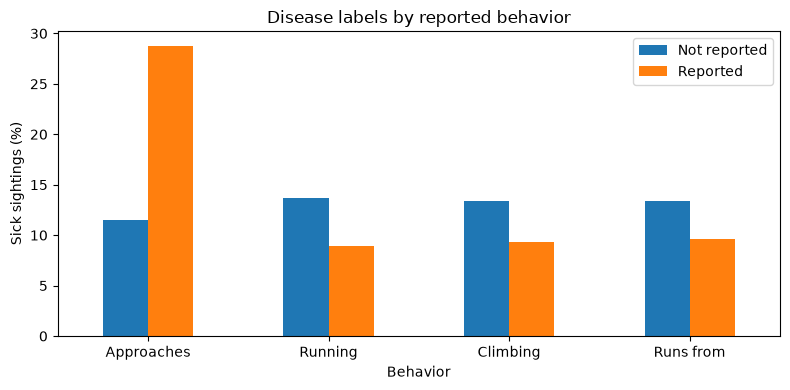

sightings  sick_sightings  sick_rate
Behavior   Reported                                      
Approaches False          2272             261   0.114877
           True            146              42   0.287671
Running    False          1836             251   0.136710
           True            582              52   0.089347
Climbing   False          1883             253   0.134360
           True            535              50   0.093458
Runs from  False          1875             251   0.133867
           True            543              52   0.095764

In [54]:
behaviors = ["Approaches", "Running", "Climbing", "Runs from"]

behavior_summary = pd.concat(
    {
        behavior: data.groupby(behavior)["diseased"].agg(
            sightings="size",
            sick_sightings="sum",
            sick_rate="mean",
        )
        for behavior in behaviors
    },
    names=["Behavior", "Reported"],
)

rates = behavior_summary["sick_rate"].unstack() * 100
rates.columns = ["Not reported", "Reported"]

rates.plot.bar(figsize=(8, 4), rot=0)
plt.ylabel("Sick sightings (%)")
plt.title("Disease labels by reported behavior")
plt.tight_layout()
plt.show()

behavior_summary

We compare disease rates for sightings where each behavior was reported and where it was not reported. We also check group sizes. A False value means the behavior was not recorded, so the volunteer may not have observed it. About 29% of sightings where the squirrel approached people are labeled sick, compared with about 12% where this behavior was not reported. Running, climbing, and running away from people are associated with smaller decreases in the sick rate. Approaches shows the largest difference among these four behaviors and looks promising. Approaching people alone does not establish aggression.

## Weather and disease labels

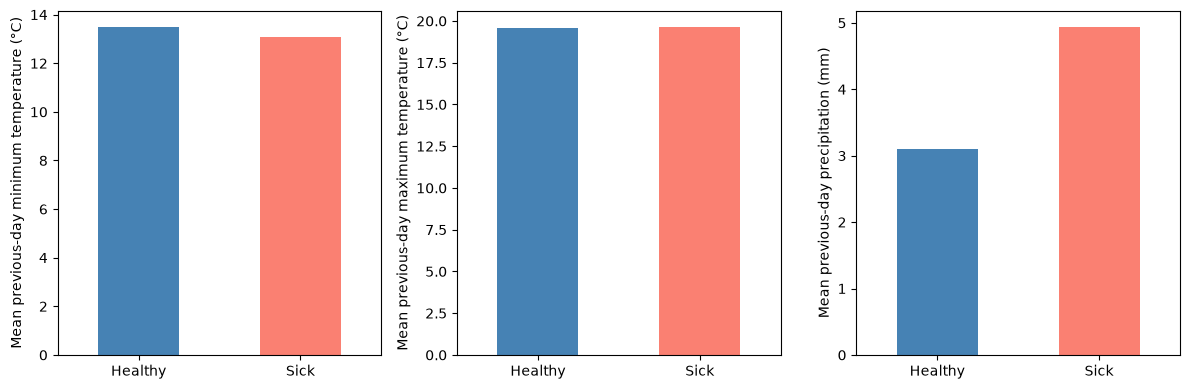

,prev_tmin_c,prev_tmax_c,prev_precip_mm
Healthy,13.47,19.58,3.11
Sick,13.09,19.61,4.93


In [55]:
weather_columns = ["prev_tmin_c", "prev_tmax_c", "prev_precip_mm"]
weather_labels = [
    "Mean previous-day minimum temperature (°C)",
    "Mean previous-day maximum temperature (°C)",
    "Mean previous-day precipitation (mm)",
]

weather_means = data.groupby("diseased")[weather_columns].mean()
weather_means.index = ["Healthy", "Sick"]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, column, label in zip(axes, weather_columns, weather_labels):
    weather_means[column].plot.bar(
        ax=ax, color=["steelblue", "salmon"], rot=0
    )
    ax.set_xlabel("")
    ax.set_ylabel(label)
    ax.set_ylim(bottom=0)

plt.tight_layout()
plt.show()

weather_means.round(2)

Average previous-day minimum and maximum temperatures are similar for healthy and sick sightings. Average precipitation is higher for sick sightings, at about 4.9 mm compared with 3.1 mm for healthy sightings. Many sightings share the same daily weather values, so this difference may reflect particular observation dates. We will check whether weather improves predictions during model evaluation.

## Park events and disease labels

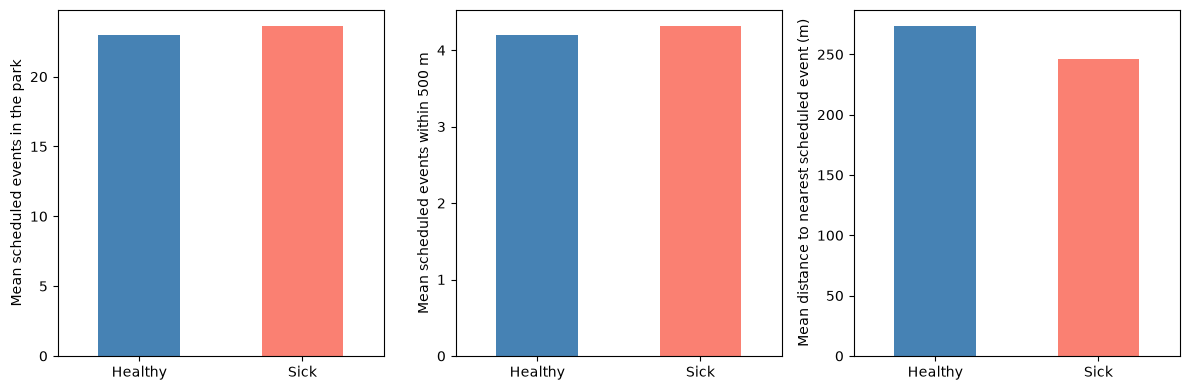

,park_event_count,nearby_event_count,nearest_event_meters
Healthy,22.99,4.19,273.12
Sick,23.59,4.31,246.46


In [56]:
event_columns = [
    "park_event_count",
    "nearby_event_count",
    "nearest_event_meters",
]
event_labels = [
    "Mean scheduled events in the park",
    "Mean scheduled events within 500 m",
    "Mean distance to nearest scheduled event (m)",
]

event_means = data.groupby("diseased")[event_columns].mean()
event_means.index = ["Healthy", "Sick"]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, column, label in zip(axes, event_columns, event_labels):
    event_means[column].plot.bar(
        ax=ax, color=["steelblue", "salmon"], rot=0
    )
    ax.set_xlabel("")
    ax.set_ylabel(label)
    ax.set_ylim(bottom=0)

plt.tight_layout()
plt.show()

event_means.round(2)

Healthy and sick sightings have similar average park-wide and nearby event counts. Sick sightings are slightly closer to the nearest scheduled event, averaging about 246 m compared with 273 m for healthy sightings. These differences are small, so we will check whether event features improve predictions when combined with other features. Event locations are approximate, and permits describe scheduled activity with unknown attendance.

# How would you solve this problem manually

We would review each report’s behavior fields and written notes for aggression, unusual behavior, or visible signs of illness. Reports with several concerning observations would receive higher priority, while vague descriptions would need more information. We would use the sighting’s time and location to decide whether staff could still find the squirrel and compare nearby reports for possible duplicates.

With only 40–50 captures available per day, we would rank reports by concern and use location to plan trips efficiently. Missing a sick squirrel is the more serious mistake, so uncertain reports with concerning details would remain on the list for review. We would record capture and test results and compare them with the original observations to learn which signs are most useful. The patterns found in our training data, such as fur color and approaching people, could inform this review, but would need validation before guiding field decisions.

# Sick rate by day

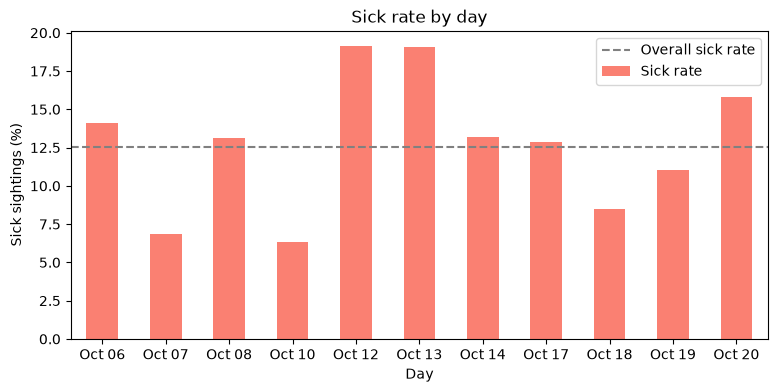

In [57]:
daily_rate = data.groupby("Date")["diseased"].mean() * 100
daily_rate.index = daily_rate.index.strftime("%b %d")

daily_rate.plot.bar(color="salmon", rot=0, figsize=(9, 4), label="Sick rate")
plt.axhline(data["diseased"].mean() * 100, color="gray", linestyle="--", label="Overall sick rate")
plt.xlabel("Day")
plt.ylabel("Sick sightings (%)")
plt.title("Sick rate by day")
plt.legend()
plt.show()

The sick rate starts at 14% on Oct 6, drops to about 7% on Oct 7 and 6% Oct 10 and then jumps to its highest point on Oct 12 and 13 (about 19%). After that it falls to 8.5% on Oct 18 and climbs back to 15.8% on Oct 20 although Oct 20 has only 57 sightings. The rate rises and falls but does not keep climbing. The first half of the days Oct 6-13 has a 12.8% sick rate and the second half Oct 14-20 has 12%. The highest shares of sick-labeled sightings occurred on October 12 and 13, which also had the highest previous-day rainfall. The daily rates showed no steady increase over the observation period.

# Text Processing

We combine all four text fields to explore common words and search for mentions of chasing or injury. For behavior similarity, we use `Other Activities`, `Other Interactions`, and `Specific Location` together because observers sometimes describe actions in their location notes. We also examine `Color notes` separately for descriptions of fur color and tails.

In [58]:
nlp = spacy.load("en_core_web_lg")

# Put the four free text columns into one note per sighting.
text_columns = ["Color notes", "Specific Location", "Other Activities", "Other Interactions"]
notes = data[text_columns].fillna("").agg(" ".join, axis=1).str.strip()
has_text = notes != ""

# How many words are in each note, for healthy vs sick sightings (only sightings with text).
word_count = notes.str.split().str.len()
word_count[has_text].groupby(data["diseased"]).describe()

,count,mean,std,min,25%,50%,75%,max
diseased,,,,,,,,
False,732.0,4.653005,4.019423,1.0,2.0,3.0,6.0,27.0
True,132.0,5.098485,4.387456,1.0,2.0,4.0,7.0,27.0


In each note for each sick sighting the word count is slightly longer than false nutosis sightings. However, its coming from the mean and 50% columns. The difference between true nutosis and false nutosis sightings are minimal. 

In [59]:
# Most common words in healthy vs sick notes, leaving out filler words like "the" and "on".
words = notes.str.lower().str.findall(r"[a-z]+").explode().dropna()
words = words[~words.isin(nlp.Defaults.stop_words)]
is_sick = data.loc[words.index, "diseased"]

pd.DataFrame({
    "Healthy word": words[~is_sick].value_counts().head(10).index,
    "Healthy %": (words[~is_sick].value_counts(normalize=True).head(10).values * 100).round(1),
    "Sick word": words[is_sick].value_counts().head(10).index,
    "Sick %": (words[is_sick].value_counts(normalize=True).head(10).values * 100).round(1),
})

,Healthy word,Healthy %,Sick word,Sick %
0,tree,10.6,tree,5.3
1,selected,3.4,tail,3.0
2,cinnamon,3.0,white,3.0
3,white,2.2,fence,2.5
4,gray,2.1,digging,2.1
5,primary,2.0,cinnamon,2.1
6,highlights,1.8,chasing,1.8
7,runs,1.7,dog,1.4
8,executive,1.7,gray,1.4
9,adjustments,1.7,selected,1.4


In [60]:
def texts_to_vectors(texts, exclude_stop=False, exclude_punct=True):
    """Embed each string as spaCy's averaged token vector; empty/NaN -> zero vector."""
    cleaned = texts.fillna("").astype(str).tolist()
    vectors = []
    for doc in nlp.pipe(cleaned):
        tokens = [t for t in doc if t.has_vector and not (exclude_stop and t.is_stop) and not (exclude_punct and t.is_punct)]
        vectors.append(np.mean([t.vector for t in tokens], axis=0) if tokens else np.zeros(nlp.vocab.vectors_length))
    return np.array(vectors)

# One note -> one 300 number vector
sample_note = notes[has_text].iloc[0]
sample_vec = texts_to_vectors(pd.Series([sample_note]))
sample_note, sample_vec.shape, sample_vec[0, :10]

('dark gray in tree',
 (1, 300),
 array([ 0.11984176,  0.0734375 , -0.05725375, -0.14129576,  0.13698976,
        -0.04110499, -0.08645251,  0.12274   , -0.15845   ,  1.6014324 ],
       dtype=float32))

In [61]:
# Cosine similarity between a few example phrases: close to 1 means similar meaning, close to 0 means unrelated.
example_notes = pd.Series(["scared", "bit scared", "curious", "eating nut", "foraging"])
sims = cosine_similarity(texts_to_vectors(example_notes))
pd.DataFrame(sims, index=example_notes, columns=example_notes).round(2)

,scared,bit scared,curious,eating nut,foraging
scared,1.00,0.87,0.54,0.37,0.03
bit scared,0.87,1.00,0.62,0.45,0.08
curious,0.54,0.62,1.00,0.38,0.22
eating nut,0.37,0.45,0.38,1.00,0.33
foraging,0.03,0.08,0.22,0.33,1.00


Only 864 of the 2,418 training sightings have any text which 132 are actually sick from Nutosis. Notes from sick sightings are only a little longer than notes from healthy ones (median 4 words vs 3). The most common words are mostly about where the squirrel was tree, fence and its color was cinnamon, white, gray. Words like selected, executive, and adjustments come from volunteers fixing the color entry, not from the squirrel. Sick notes use tail, digging, chasing, and dog more often, but each of these is only 1-3% of the words. Cosine similarity shows that scared and bit scared have 0.87 similarity, while scared and foraging have only 0.03. This lets a model treat different wordings of the same behavior as similar.

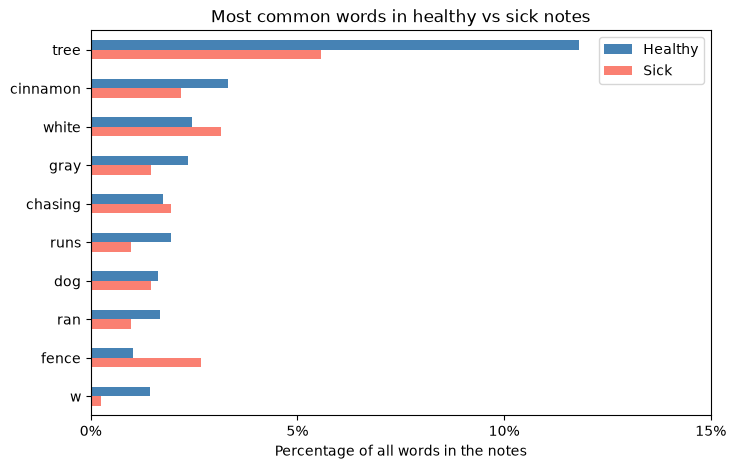

In [62]:
entry_words = ["selected", "executive", "adjustments", "primary", "highlights"]
behavior_words = words[~words.isin(entry_words)]
behavior_sick = data.loc[behavior_words.index, "diseased"]

top_words = behavior_words.value_counts().head(10).index
word_share = pd.DataFrame({
    "Healthy": behavior_words[~behavior_sick].value_counts(normalize=True),
    "Sick": behavior_words[behavior_sick].value_counts(normalize=True),
}).reindex(top_words).fillna(0) * 100

word_share.plot.barh(color=["steelblue", "salmon"], figsize=(8, 5))
plt.gca().invert_yaxis()
plt.xlim(0, 15)
plt.xticks([0, 5, 10, 15], ["0%", "5%", "10%", "15%"])
plt.xlabel("Percentage of all words in the notes")
plt.title("Most common words in healthy vs sick notes")
plt.show()

The most common words for both sick and healthy contain the location, fur colors and the action (running/chasing). Obviously, the most common word is tree since squirrels are commonly on trees or near them. On this graph white fur overtook healthy, which means out of the sick notes its more common to see white fur in it. Its worth looking more into with Nutosis true sightings. The word “fence” accounts for a larger share of words in notes from sick-labeled sightings.

In [63]:
all_notes = data[text_columns].fillna("").agg(" ".join, axis=1)

chase_mentioned = all_notes.str.contains(
    r"chas", case=False, na=False
)

pd.crosstab(
    chase_mentioned,
    data["diseased"],
    rownames=["Chasing mentioned"],
    colnames=["Diseased"],
    margins=True
)

Diseased,False,True,All
Chasing mentioned,,,
False,2061,292,2353
True,54,11,65
All,2115,303,2418


In [64]:
has_text = all_notes.str.strip() != ""

pd.crosstab(
    chase_mentioned[has_text],
    data.loc[has_text, "diseased"],
    rownames=["Chasing mentioned"],
    colnames=["Diseased"],
    margins=True
)

Diseased,False,True,All
Chasing mentioned,,,
False,678,121,799
True,54,11,65
All,732,132,864


Among sightings with written notes, 16.9% were labeled sick when chasing was mentioned, compared with 15.1% when it was not. The gap was larger when empty notes were included. Some notes describe the squirrel chasing another animal, while others describe the squirrel being chased.

In [65]:
behavior_notes = data[
    ["Specific Location", "Other Activities", "Other Interactions"]
].fillna("").agg(" ".join, axis=1).str.strip()

behavior_notes = behavior_notes[behavior_notes != ""]

concepts = pd.Series([
    "aggressive behavior, attacking, biting",
    "fearful behavior, escaping, avoiding",
    "playful behavior, playing"
])

similarities = cosine_similarity(
    texts_to_vectors(behavior_notes),
    texts_to_vectors(concepts)
)

behavior_similarity = pd.DataFrame(
    similarities,
    index=behavior_notes.index,
    columns=["Aggression", "Fear", "Play"]
)

behavior_similarity.insert(0, "Note", behavior_notes)

behavior_similarity.sort_values(
    "Aggression", ascending=False
).head(10)

,Note,Aggression,Fear,Play
493,teasing barking dog indifferent by not caring ...,0.698128,0.660076,0.706573
144,"eating (a mushroom),circles around us,really f...",0.633003,0.618256,0.650703
974,avoiding a dog,0.627069,0.676236,0.587492
215,"indifferent (mostly,did notice me,busy eating,...",0.614867,0.647479,0.609024
1124,new movement flailing arms while foraging,0.609671,0.568778,0.554344
1560,"indifferent (noticed me,busy eating,foraging)",0.607039,0.652189,0.602785
922,chasing (dog chasing),0.603130,0.559371,0.532814
1695,people feeding squirrel,0.597160,0.591845,0.539704
1656,"being chased,was pushed by other squirrel",0.583447,0.578732,0.526320
675,"cautious,observant,runs off",0.580791,0.567545,0.532649


In [66]:
behavior_similarity["diseased"] = data.loc[
    behavior_similarity.index, "diseased"
]

behavior_similarity.groupby("diseased")[
    ["Aggression", "Fear", "Play"]
].mean()

,Aggression,Fear,Play
diseased,,,
False,0.378987,0.390114,0.396526
True,0.410795,0.424357,0.415454


In [67]:
behavior_similarity.groupby("diseased")["Aggression"].describe()

,count,mean,std,min,25%,50%,75%,max
diseased,,,,,,,,
False,669.0,0.378987,0.098104,0.002517,0.312523,0.383917,0.454259,0.627069
True,120.0,0.410795,0.109754,0.080149,0.340940,0.410644,0.494020,0.698128


In [68]:
behavior_similarity[["Aggression", "Fear", "Play"]].corr()

,Aggression,Fear,Play
Aggression,1.000000,0.928637,0.822060
Fear,0.928637,1.000000,0.704071
Play,0.822060,0.704071,1.000000


Mean aggression similarity was slightly higher for sick-labeled sightings (0.411) than for healthy-labeled sightings (0.379), but the two groups overlapped. Even “avoiding a dog” appeared among the ten highest aggression scores. Aggression and fear scores were also strongly correlated (0.93). We will test whether these scores help predict disease labels during validation.

In [69]:
color_text = data["Color notes"].fillna("").str.lower()

results = []

for term in ["white", "gray", "cinnamon", "black", "brown", "fur", "tail"]:
    mentioned = color_text.str.contains(r"\b" + term + r"\b", na=False)

    results.append({
        "Term": term,
        "Sightings": mentioned.sum(),
        "Sick sightings": data.loc[mentioned, "diseased"].sum(),
        "Sick rate (%)": data.loc[mentioned, "diseased"].mean() * 100
    })

pd.DataFrame(results).round(1)

,Term,Sightings,Sick sightings,Sick rate (%)
0,white,56,11,19.6
1,gray,45,6,13.3
2,cinnamon,61,8,13.1
3,black,13,2,15.4
4,brown,8,3,37.5
5,fur,1,0,0.0
6,tail,26,12,46.2


In [70]:
physical_mentions = all_notes.str.contains(
    r"injur|wound|no tail|missing tail|\.5 of a tail",
    case=False,
    na=False
)

pd.DataFrame({
    "Note": all_notes[physical_mentions],
    "Diseased": data.loc[physical_mentions, "diseased"]
})

,Note,Diseased
124,No Tail! bench,True
651,injured not moving,True
922,Partial missing tail chasing (dog chasing),True
2139,had .5 of a tail,True


Of the 26 color notes mentioning a tail, 12 were labeled sick. Some described tail color, while three described a missing or partial tail. All three were labeled sick, as was one separate sighting described as “injured.” These four sightings are too few to draw a general conclusion.

In [71]:
has_behavior_text = data.index.isin(behavior_notes.index)

pd.crosstab(
    has_behavior_text,
    data["diseased"],
    rownames=["Has behavior text"],
    colnames=["Diseased"],
    margins=True
)

Diseased,False,True,All
Has behavior text,,,
False,1446,183,1629
True,669,120,789
All,2115,303,2418


Only 789 of the 2,418 training sightings have notes in the three fields used for behavior similarity. We keep all sightings. During preparation, we will set the three similarity scores to 0 when those fields are empty and use `has_behavior_text` to distinguish missing notes from a measured score of 0.